# Etapa 9. Servicio y visualización (Trie, Top-K y dashboard)

Proyecto EDA 2026-2 · Grupo 1 · Escenario B (comercio electrónico)
Responsable de la etapa 9: Jesús.

Esta etapa es la capa de servicio de cara al usuario final: reúne las salidas de las etapas anteriores en una API y en un dashboard. Implementa:

1. **Autocompletado de prefijos en tiempo real:** un **Trie** radix con una caché Top-K en cada nodo, que responde un prefijo de largo $L$ en $O(L + k)$, y búsqueda difusa Damerau-Levenshtein (OSA) para los errores de tipeo.
2. **Ranking Top-K multicriterio con MinHeap acotado:** selección en $O(N \log K)$ frente al ordenamiento completo en $O(N \log N)$, sobre un score que combina la similitud de atributos (HNSW, etapa 7), el comportamiento (MinHash + LSH, etapa 7), la autoridad (PageRank, etapa 8) y la co-compra (etapa 8).
3. **Panel de ventas, actividad y alertas:** ventas y actividad por día, productos más vendidos, stock y disponibilidad (etapa 3) y alertas de fraude (etapa 6), como pide el escenario B.
4. **Dashboard:** `visualizador/dashboard_etapa_9_servicio.html`, un archivo HTML que se abre sin servidor.

## Función de la etapa en el pipeline

| Archivo o código | Origen | Uso en el servicio |
| --- | --- | --- |
| `etapa2_eventos.jsonl` | Etapa 2 | Ventas y actividad por día del panel |
| `catalogo.jsonl` (`AlmacenCatalogo`) y `estado_productos.parquet` | Etapa 3 | Fichas de producto, stock y disponibilidad |
| `indice_precio.bpt` (`ArbolBMas`) | Etapa 4 | Filtro por rango de precio en la recomendación y la búsqueda |
| `vectores.npz` (`IndiceProductos`) | Etapa 5 | Arranque en frío: KNN exacto por atributos para productos sin actividad en el stream |
| `alertas.jsonl` y `ordenes_bloqueadas.json` | Etapa 6 | Panel de fraude; las compras bloqueadas no cuentan como ventas |
| `similares.parquet` y `relacionados.parquet` | Etapa 7 | Señales S_sim y S_rel del scoring |
| `grafo_cocompra.npz`, `pagerank.parquet` y `comunidades.parquet` | Etapa 8 | Señales S_co y S_pr, y comunidad del producto |

Las etapas 0 y 1 llegan a través de la 2: el stream sin pérdidas de la etapa 0, limpio y deduplicado por la etapa 1, es el que la etapa 2 entrega en orden de servicio.

## Pasos del notebook

1. Configuración y entrada.
2. Trie (árbol de prefijos).
3. Top-K con MinHeap.
4. Scoring híbrido multicriterio.
5. Servicio: recomendación, filtro por precio y arranque en frío.
6. Panel de ventas y actividad.
7. Monitoreo de fraude.
8. Salidas de la etapa 9 y dashboard.
9. Experimentos de escalabilidad.
10. Auditoría técnica y calibración del scoring.

## Paso 1. Configuración y entrada

El código de la etapa está en `src/etapa_9/`: `service.py` (Trie, Top-K, scoring, servicio, panel y orquestación), `dashboard.py` con su plantilla `plantilla_dashboard.html`, `benchmark.py` (experimentos del paso 9) y `evaluacion_scoring.py`, `evaluacion_real.py` y `analisis_campos_reales.py` (paso 10). La salida se guarda en `data/interim/<CATEGORIA>/etapa_9/` y los resultados de los experimentos en `results/etapa_9/`.

Los experimentos se reutilizan si sus resultados existen y son de la versión actual; si no, se miden de nuevo. Para medir todo otra vez se cambia `REEJECUTAR_EXPERIMENTOS` a `True` en la segunda celda de código. La categoría y la semilla salen de `src/config.py`.

In [1]:
import json
import platform
import sys
import time
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.etapa_9 import analisis_campos_reales, benchmark, evaluacion_real, evaluacion_scoring
from src.etapa_9.dashboard import RUTA_DASHBOARD
from src.etapa_9.service import (
    IndiceInvertido,
    NodoTrie,
    ScoringHibrido,
    ServicioEcommerce,
    TopKHeap,
    Trie,
    ejecutar_etapa,
    normalizar_texto,
    similitud_desde_distancia,
    tokenizar,
)

CATEGORIA = config.CATEGORIA
SEED = config.SEED
DIR_INTERIM = config.CARPETA_INTERIM
DIR_ETAPA9 = DIR_INTERIM / "etapa_9"
DIR_RESULTADOS = config.CARPETA_RESULTADOS / "etapa_9"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor() or platform.machine(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}
print(f"Categoría: {CATEGORIA}   semilla: {SEED}")
PLATAFORMA

Categoría: Office_Products   semilla: 42


{'sistema': 'Windows-10-10.0.19045-SP0',
 'procesador': 'AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD',
 'nucleos': 8,
 'ram_gb': 32.1,
 'python': '3.12.0',
 'semilla': 42}

In [2]:
# Protocolo de persistencia y reutilización de mediciones
# Las mediciones guardadas en results/etapa_9/ se reutilizan. Con True se miden de nuevo.
REEJECUTAR_EXPERIMENTOS = False
R = DIR_RESULTADOS


def resultados(ruta, medir_tabla, requeridas=()):
    """Lee la tabla de resultados si existe y tiene las columnas `requeridas`. Si no, la mide con
    medir_tabla() y la guarda con la plataforma."""
    if ruta.exists() and not REEJECUTAR_EXPERIMENTOS:
        tabla = pd.read_csv(ruta, dtype={"procesador": str, "python": str})
        if all(c in tabla.columns for c in requeridas):
            print(f"Resultados leídos de {ruta.name}")
            return tabla
        print(f"{ruta.name} es de una versión anterior del experimento y se mide de nuevo")
    tabla = medir_tabla().assign(procesador=PLATAFORMA["procesador"], python=PLATAFORMA["python"])
    tabla.to_csv(ruta, index=False)
    print(f"Resultados guardados en {ruta.name}")
    return tabla


def resultados_archivos(rutas, ejecutar, vigente=lambda: True):
    """Reutiliza los archivos que escribe un script de src/etapa_9/ si existen y están vigentes;
    si no, ejecuta el script."""
    if not REEJECUTAR_EXPERIMENTOS and all(r.exists() for r in rutas) and vigente():
        print("Resultados leídos de", ", ".join(r.name for r in rutas))
        return
    ejecutar()
    print("Resultados guardados en", ", ".join(r.name for r in rutas))


def plataforma_de(tabla):
    """Procesador y versión de Python con que se midió una tabla de resultados."""
    if "procesador" in tabla.columns and "python" in tabla.columns:
        return f"{tabla['procesador'].iloc[0]}, Python {tabla['python'].iloc[0]}"
    return f"{PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}"

## Paso 2. Estructura de Datos Trie (Árbol de Prefijos)

El **Trie** (Fredkin, 1960) organiza el vocabulario del catálogo estructurado como un árbol donde cada arista representa un carácter. 

**Optimización de latencia con Top-K Caché Local:**
En un Trie estándar, resolver un prefijo de longitud $L$ requiere descender hasta el nodo del prefijo en $O(L)$ y luego recorrer exhaustivamente el subárbol descendente para encontrar las mejores palabras ($O(L + |\text{subárbol}| \log K)$). Para garantizar respuesta instantánea (*search-as-you-type*), cada nodo mantiene una caché local con las $M$ sugerencias de mayor frecuencia que transitan por él, reduciendo la complejidad de consulta estrictamente a $O(L)$, independiente del tamaño del vocabulario.


In [3]:
# 2.1 Demostración de Trie con Top-K Caché
trie_demo = Trie(capacidad_cache=5)

# Insertar términos con frecuencias de popularidad
terminos_muestra = [
    ("toner brother tn436", 500.0, {"asin": "B0BF98LWMZ", "cat": "Toner"}),
    ("toner hp laserjet", 420.0, {"asin": "B01F3M964Y", "cat": "Toner"}),
    ("toner canon imageclass", 310.0, {"asin": "B00DY8P67W", "cat": "Toner"}),
    ("tinta epson ecotank", 290.0, {"asin": "B07KPL8Q91", "cat": "Tinta"}),
    ("tijeras de oficina scotch", 180.0, {"asin": "B00006IE5D", "cat": "Papelería"}),
    ("papel bond 500 hojas", 400.0, {"asin": "B001PMHZZ6", "cat": "Papel"}),
    ("papel fotográfico glossy", 150.0, {"asin": "B09MHP71BG", "cat": "Papel"}),
]

for term, freq, meta in terminos_muestra:
    trie_demo.insertar(term, frecuencia=freq, meta=meta)

print(f"Términos indexados en Trie demo: {len(trie_demo)}")

# Consultar prefijo 'ton'
sugerencias_ton = trie_demo.autocompletar("ton", k=3)
print("\nSugerencias de autocompletado para prefijo 'ton':")
display(pd.DataFrame(sugerencias_ton))

# Consultar prefijo 'pap'
sugerencias_pap = trie_demo.autocompletar("pap", k=3)
print("\nSugerencias de autocompletado para prefijo 'pap':")
display(pd.DataFrame(sugerencias_pap))


Términos indexados en Trie demo: 7

Sugerencias de autocompletado para prefijo 'ton':


,termino,frecuencia,meta
0,toner brother tn436,500.0,"{'asin': 'B0BF98LWMZ', 'cat': 'Toner'}"
1,toner hp laserjet,420.0,"{'asin': 'B01F3M964Y', 'cat': 'Toner'}"
2,toner canon imageclass,310.0,"{'asin': 'B00DY8P67W', 'cat': 'Toner'}"



Sugerencias de autocompletado para prefijo 'pap':


,termino,frecuencia,meta
0,papel bond 500 hojas,400.0,"{'asin': 'B001PMHZZ6', 'cat': 'Papel'}"
1,papel fotográfico glossy,150.0,"{'asin': 'B09MHP71BG', 'cat': 'Papel'}"


## Paso 3. Estructura de Datos Top-K con MinHeap

Para clasificar los $K$ mejores productos entre $N$ candidatos:
- Ordenar la lista completa con `sorted()` cuesta $O(N \log N)$ tiempo y $O(N)$ espacio.
- La estructura **TopKHeap** mantiene un `MinHeap` de tamaño acotado $K$. Al evaluar cada candidato con score $s$:
  - Si el heap tiene menos de $K$ elementos, se inserta en $O(\log K)$.
  - Si ya contiene $K$ elementos y $s > \text{raíz.score}$, se reemplaza la raíz en $O(\log K)$.
  - De lo contrario, se descarta en $O(1)$.
- Complejidad total: **$O(N \log K)$** en tiempo y **$O(K)$** en espacio auxiliar. Cuando $N = 10^6$ y $K = 10$, $N \log K \approx 3.3 \times 10^6$ operaciones frente a $N \log N \approx 20 \times 10^6$ de un ordenamiento completo, logrando una aceleración de más de 3×.


In [4]:
# 3.1 Demostración de TopKHeap
topk_demo = TopKHeap(k=3)
candidatos_demo = [
    ("Producto Alfa", 0.42),
    ("Producto Beta", 0.89),
    ("Producto Gamma", 0.15),
    ("Producto Delta", 0.96),
    ("Producto Epsilon", 0.73),
]

for item, score in candidatos_demo:
    topk_demo.agregar(item, score)

print("Top 3 elementos seleccionados:")
for score, item in topk_demo.obtener_top():
    print(f"  Score: {score:.2f} -> {item}")


Top 3 elementos seleccionados:
  Score: 0.96 -> Producto Delta
  Score: 0.89 -> Producto Beta
  Score: 0.73 -> Producto Epsilon


## Paso 4. Función de scoring híbrido multicriterio

La relevancia de un producto candidato $p$ respecto a un producto ancla $q$ se calcula mediante una combinación lineal convexa de cuatro señales del pipeline:

$$S(p \mid q) = w_{\text{sim}} \cdot S_{\text{sim}}(p, q) + w_{\text{rel}} \cdot S_{\text{rel}}(p, q) + w_{\text{pr}} \cdot \widetilde{S}_{\text{pr}}(p) + w_{\text{co}} \cdot S_{\text{co}}(p, q)$$

donde:
- $S_{\text{sim}}(p, q) = \max(0, 1 - d^2/2)$: coseno entre los vectores de atributos (título, categoría y tienda) de la etapa 7. HNSW devuelve la distancia euclidiana $d = \sqrt{2 - 2\cos}$ entre vectores de norma 1, así que $\cos = 1 - d^2/2$. La versión anterior usaba $1 - d$, que vale 0 para todo coseno menor o igual que 0.5 (revisión técnica, punto 1.5).
- $S_{\text{rel}}(p, q) = J(p, q)$: Jaccard de los usuarios, de los relacionados de MinHash + LSH (etapa 7).
- $\widetilde{S}_{\text{pr}}(p)$: PageRank de la etapa 8 en escala logarítmica, llevado a $[0, 1]$ con el mínimo y el máximo del grafo (`NORMALIZACION_PAGERANK = "log"`). Con PageRank dividido por el máximo, la mediana quedaba en 0.008 y la señal solo pesaba en los hubs.
- $S_{\text{co}}(p, q) = \frac{w_{pq}}{\max_k w_{qk}}$: afinidad directa de co-compra en el CSR de la etapa 8.
- Pesos base: $w_{\text{sim}} = 0.35, w_{\text{rel}} = 0.25, w_{\text{pr}} = 0.20, w_{\text{co}} = 0.20$. Son una elección de diseño, no el resultado de una calibración. Una señal que el ancla no tiene se anula y los pesos se renormalizan. El paso 10 compara estos pesos con los aprendidos por regresión logística, que solo se adoptan si cumplen la regla fijada antes de medir: con S_sim corregido la regla se cumple, pero los pesos base se mantienen por una decisión declarada en la lectura del paso 10.
- Premio a la novedad: después del scoring, el ranking se reordena con $(1 - \lambda) \cdot S + \lambda \cdot (1 - \widetilde{S}_{\text{pr}})$ y $\lambda = 0.3$, para no recomendar siempre los mismos productos populares.

In [5]:
# 4.1 Evaluación de Scoring Híbrido
scoring = ScoringHibrido(
    peso_similitud=0.35,
    peso_relacionados=0.25,
    peso_pagerank=0.20,
    peso_cocompra=0.20,
)

s1 = scoring.calcular_score(similitud_atributos=0.85, jaccard_comportamiento=0.12, pagerank_normalizado=0.90, afinidad_cocompra=0.75)
s2 = scoring.calcular_score(similitud_atributos=0.30, jaccard_comportamiento=0.01, pagerank_normalizado=0.10, afinidad_cocompra=0.00)

print(f"Score Producto Relevante y Conectado: {s1:.4f}")
print(f"Score Producto Poco Relacionado:      {s2:.4f}")


Score Producto Relevante y Conectado: 0.6575
Score Producto Poco Relacionado:      0.1275


## Paso 5. Servicio: recomendación, filtro por precio y arranque en frío

La clase `ServicioEcommerce` carga los artefactos de las etapas 3 a 8 y responde las consultas del escenario B:
- **Recomendación híbrida (5.2).** Los candidatos son los vecinos HNSW, los relacionados de MinHash + LSH y los vecinos de co-compra del ancla; el `TopKHeap` elige los K de mayor score.
- **Filtro por rango de precio (5.3).** `recomendar` y `buscar` aceptan `precio_min` y `precio_max`. El rango se resuelve con una consulta al B+Tree en disco de la etapa 4, que recorre las hojas enlazadas en $O(\log_B n + r/B)$ lecturas de página, y los candidatos se filtran con ese conjunto.
- **Arranque en frío (5.4).** Un producto que nunca apareció en el stream no tiene vecinos HNSW, firma MinHash ni co-compras. Para él la lista sale del KNN exacto por atributos (precio, calificación, popularidad y actividad) dentro de su categoría, con el KD-Tree de la etapa 5 reconstruido desde `vectores.npz`. Las anclas con señales siguen con el scoring híbrido.
- **Stock y disponibilidad.** Cada ficha y cada recomendación llevan el stock y la disponibilidad de la etapa 3.

In [6]:
# 5.1 Carga del servicio
servicio = ServicioEcommerce(RAIZ / "data" / "interim", categoria=CATEGORIA)
servicio.cargar_datos()  # catálogo completo (antes 50 000 inserciones, ~3 % del catálogo)

print(f"Términos en Trie: {len(servicio.trie):,}")
print(f"Productos con PageRank: {len(servicio._pagerank):,}")
print(f"Productos con Similares HNSW: {len(servicio._similares):,}")
print(f"Productos con Relacionados LSH: {len(servicio._relacionados):,}")
print(f"Productos con estado en la etapa 3: {len(servicio._estado):,}")
print(f"Productos en el índice de precios de la etapa 4: {len(servicio.indice_precio):,}")
print(f"Productos en el índice de atributos de la etapa 5: {len(servicio.indice_atributos.asins):,}")

ServicioEcommerce inicializado en 103.57 s
Términos en Trie: 585,983
Productos con PageRank: 150,534
Productos con Similares HNSW: 195,019
Productos con Relacionados LSH: 75,890
Productos con estado en la etapa 3: 195,019
Productos en el índice de precios de la etapa 4: 336,415
Productos en el índice de atributos de la etapa 5: 336,415


In [7]:
# 5.2 Recomendación híbrida Top-K para el producto de mayor PageRank (B0BF98LWMZ)
recs_top1 = servicio.recomendar("B0BF98LWMZ", k=8)
df_recs = pd.DataFrame(recs_top1)[[
    "rango", "parent_asin", "score_hibrido", "similitud_atributos",
    "jaccard_comportamiento", "afinidad_cocompra", "pagerank", "stock", "titulo", "precio"
]]
print("Top-K recomendaciones híbridas para el tóner compatible TN436 (B0BF98LWMZ):")
display(df_recs)

Top-K recomendaciones híbridas para el tóner compatible TN436 (B0BF98LWMZ):


,rango,parent_asin,score_hibrido,similitud_atributos,jaccard_comportamiento,afinidad_cocompra,pagerank,stock,titulo,precio
0,1,B07B2TKVJ5,0.8053,0.6599,0.0000,0.0,0.000009,1,Cool Toner Compatible TN433 Toner Cartridge Re...,59.32
1,2,B0CB9J3J2P,0.7920,0.0000,0.0235,1.0,0.000067,15,EasyGo Rolling Cart Folding Grocery Shopping C...,70.63
2,3,B0851735GB,0.7907,0.6416,0.0000,0.0,0.000008,31,v4ink Compatible TN-433 TN-431 Toner Cartridge...,59.99
3,4,B07W5DWRQN,0.7898,0.6540,0.0000,0.0,0.000005,16,myCartridge Compatible Toner Cartridge Replace...,65.90
4,5,B091K61Y4Q,0.7807,0.6418,0.0000,0.0,0.000005,0,E-Z Ink (TM) Compatible Toner Cartridge Replac...,40.99
5,6,B08VXJSY59,0.7787,0.6205,0.0000,0.0,0.000010,1,E-Z Ink (TM Compatible Toner Cartridge Replace...,67.99
6,7,B08S31HNS2,0.7715,0.6444,0.0000,0.0,0.000003,28,E-Z Ink (TM Compatible Toner Cartridge Replace...,21.99
7,8,B08RYZ9L18,0.7673,0.6616,0.0000,0.0,0.000000,18,Valuetoner TN433 Toner Cartridge Replacement f...,NaN


In [8]:
# 5.3 Recomendación y búsqueda con filtro por rango de precio (B+Tree de la etapa 4)
ancla = "B0BF98LWMZ"
precio_ancla = servicio.detalle_producto(ancla)["precio"]
lecturas_previas = servicio.indice_precio.lecturas
t0 = time.perf_counter()
en_rango = servicio.productos_en_rango_precio(0.0, precio_ancla)
ms_rango = (time.perf_counter() - t0) * 1e3
print(f"Productos con precio entre $0 y ${precio_ancla:.2f}: {len(en_rango):,} "
      f"({ms_rango:.1f} ms y {servicio.indice_precio.lecturas - lecturas_previas:,} páginas leídas del B+Tree)")
display(pd.DataFrame(servicio.recomendar(ancla, k=8, precio_max=precio_ancla))[
    ["rango", "parent_asin", "score_hibrido", "precio", "stock", "disponible", "titulo"]])
display(pd.DataFrame(servicio.buscar("toner brother", k=5, precio_max=precio_ancla))[
    ["rango", "score", "precio", "titulo", "tienda"]])

Productos con precio entre $0 y $62.99: 281,274 (568.2 ms y 2,685 páginas leídas del B+Tree)


,rango,parent_asin,score_hibrido,precio,stock,disponible,titulo
0,1,B07B2TKVJ5,0.8053,59.32,1,True,Cool Toner Compatible TN433 Toner Cartridge Re...
1,2,B0851735GB,0.7907,59.99,31,True,v4ink Compatible TN-433 TN-431 Toner Cartridge...
2,3,B091K61Y4Q,0.7807,40.99,0,False,E-Z Ink (TM) Compatible Toner Cartridge Replac...
3,4,B08S31HNS2,0.7715,21.99,28,True,E-Z Ink (TM Compatible Toner Cartridge Replace...
4,5,B091JXDS3T,0.7530,21.99,11,True,E-Z Ink (TM Compatible Toner Cartridge Replace...
5,6,B071JF7KG8,0.7520,21.99,35,True,E-Z Ink (TM Compatible Toner Cartridge Replace...
6,7,B09V1Z8Q42,0.7303,12.99,15,True,Dirty Pop Cards - Purr-fect Pop Up Birthday Ca...
7,8,B08G51JNJB,0.6600,17.99,14,True,"Rybozen Mobile Film and Slide Scanner, Lets Yo..."


,rango,score,precio,titulo,tienda
0,1,1.0000,62.99,TN436 ColorKing Compatible Toner Cartridge Rep...,Colorking
1,2,0.9442,48.99,GOTOBY TN760 Toner Cartridge Replacement Compa...,GOTOBY
2,3,0.9412,48.99,MCYCOLOR DR730 Drum Unit Compatible Replacemen...,MCYCOLOR
3,4,0.9331,34.39,Inkalfa Compatible TN227BK TN-227BK Toner: Car...,inkalfa
4,5,0.9304,45.48,Brother Genuine Standard Yield Toner Cartridge...,Brother


In [9]:
# 5.4 Arranque en frío: producto sin actividad en el stream (KNN exacto por atributos de la etapa 5)
ancla_frio = servicio.ancla_arranque_frio()
det = servicio.detalle_producto(ancla_frio)
print(f"Ancla: {ancla_frio} · {(det['title'] or '')[:80]} · {det['categoria_hoja']} · precio {det['precio']}")
print(f"Candidatos híbridos del ancla: {len(servicio.puntuar_candidatos(ancla_frio))}")
display(pd.DataFrame(servicio.recomendar(ancla_frio, k=8))[
    ["rango", "parent_asin", "fuente", "distancia_atributos_etapa5", "precio", "categoria", "titulo"]])

Ancla: B084TPDQRR · Anthony Doerr -All The Light we Cannot See -Paperback · Book Covers & Book Accessories · precio 16.77
Candidatos híbridos del ancla: 0


,rango,parent_asin,fuente,distancia_atributos_etapa5,precio,categoria,titulo
0,1,0785242554,arranque_frio,2.3536,18.30,Book Covers & Book Accessories,Strong's Concise Concordance And Vine's Concis...
1,2,1631465783,arranque_frio,2.4940,15.19,Book Covers & Book Accessories,"The Message Deluxe Gift Bible (Leather-Look, B..."
2,3,0310821800,arranque_frio,2.6634,24.99,Book Covers & Book Accessories,Reptile Leather Extra Large Wine Bible Cover
3,4,B011DDTTUO,arranque_frio,2.6855,24.99,Book Covers & Book Accessories,"Antique Book ""Be Strong & Courageous"" Bible / ..."
4,5,0310802636,arranque_frio,2.8596,16.99,Book Covers & Book Accessories,"Adventure Bible Cover for Boys, Zippered, with..."
5,6,0310520347,arranque_frio,2.9057,15.99,Book Covers & Book Accessories,"Adventure Bible Cover for Girls, Zippered, wit..."
6,7,0310818605,arranque_frio,3.0375,12.16,Book Covers & Book Accessories,Bible Study Organizer Coal with Leather-Look A...
7,8,1250042720,arranque_frio,3.0376,NaN,Book Covers & Book Accessories,The Serger's Technique Bible: The Complete Gui...


## Paso 6. Panel de ventas y actividad

El escenario B pide un panel de ventas, actividad y alertas. `panel_ventas_actividad` lo arma con dos fuentes:
- **Ventas y actividad por día:** una pasada por el stream de la etapa 2 cuenta los eventos de cada día por tipo. Las compras de las órdenes bloqueadas por la etapa 6 se cuentan aparte y no suman ventas ni ingresos.
- **Stock y disponibilidad:** el estado de cada producto que mantiene la etapa 3, con el stock al final del stream, los agotamientos y las ventas sin stock. Esos contadores incluyen las compras fraudulentas, porque la etapa 3 se actualiza antes del filtro de la etapa 6 (limitación declarada en el informe de las etapas 3 a 5).

El mismo panel aparece en la pestaña de ventas y actividad del dashboard (paso 8).

Panel calculado en 58.3 s


,valor
dias,4.390000e+02
unidades_vendidas,1.947058e+06
ingresos,6.831143e+07
compras_bloqueadas,3.187800e+04
vistas,2.963552e+06
carritos,1.942746e+06
devoluciones,8.519500e+04
tasa_devolucion,4.375576e-02
conversion_vista_compra,6.570015e-01
productos_con_actividad,1.950190e+05


,parent_asin,titulo,categoria,unidades,ingresos,stock,disponible
0,B0BN478RWJ,HP DeskJet 2755e Wireless Color All-in-One Pri...,Inkjet Printers,2728,163652.72,15,True
1,B087S2JRXY,"Amazon Basics 15-Sheet Cross-Cut Paper, CD Cre...",Shredders,2559,337762.41,5,True
2,B0B3MX7LVG,"EZlifego Double Sided Tape Heavy Duty, Extra L...",Mounting Tape,2452,26947.48,15,True
3,B0BF98LWMZ,TN436 ColorKing Compatible Toner Cartridge Rep...,Toner Cartridges,2407,151616.93,31,True
4,B0BZ67T58M,Office Chair Wheels Replacement Rubber Chair c...,Casters,2147,85858.53,2,True
5,B09PWTVGPW,"Alientape Nano Double Sided Tape, Multipurpose...",Mounting Tape,1619,29061.05,5,True
6,B07GNNGXNK,"Gorilla Grip Desk Chair Mat, No Divots, Rollin...",Carpet Chair Mats,1615,58220.75,9,True
7,B0C36Q7PM4,"Amazon Basics Multipurpose Copy Printer Paper,...",Copy & Multipurpose Paper,1483,12590.67,14,True
8,B0BVSNVRSC,5 Pack Small White Board Dry Erase Board for K...,Dry Erase Boards,1401,28005.99,5,True
9,B082F417S1,"Leather Desk Pad Protector,Mouse Pad,Office De...",Mouse Pads,1401,16657.89,22,True


,categoria,unidades,ingresos
0,Inkjet Ink Cartridges,118798,5344609.25
1,Greeting Cards,81048,1546480.99
2,Planners,67393,1689072.72
3,Ballpoint Pens,51237,1048935.51
4,Gel Ink Rollerball Pens,48765,827807.02
5,Badge Holders,45333,702653.13
6,Mouse Pads,44844,865269.01
7,Wall Calendars,42889,1174575.98
8,Toner Cartridges,37750,2863588.24
9,Dry Erase Boards,31573,1145329.79


,parent_asin,titulo,categoria,ventas_sin_stock,agotamientos,compras
0,B09X5RYD9R,DIVERSEBEE Bible Highlighters and Pens No Blee...,Highlighters,761,134,1293
1,B09NR1SNK9,"Phomemo D30 Label Maker Machine with Tape, Por...",Label Printers,546,125,987
2,B0BZYJPRL5,"Bonsaii Shredder for Home Office, Micro Cut Pa...",Shredders,369,116,738
3,B0B75S9WGP,"Scotch Dry Erase Thermal Laminating Pouches, 5...",Dry Erase & Wet Erase Markers,329,69,644
4,B0BN44NT9S,HP 67 Black/Tri-color Ink Cartridges (2 Count ...,Inkjet Ink Cartridges,228,72,694
5,B08NXMLJR4,"AFMAT Electric Pencil Sharpener, Auto Stop, Su...",Pencil Sharpeners,211,47,708
6,B08X7JZQ7S,"3D Pop Up Birthday Cards,Warming LED Light Bir...",Greeting Cards,156,47,574
7,B0C2PQMSTP,"Mr. Pen- Aesthetic Highlighters, 8 pcs, Chisel...",Highlighters,137,43,484
8,B0C2DJVC2K,"Amazon Basics Magnetic Dry Erase White Board, ...",Dry Erase Boards,129,47,545
9,B0BCGJ5PQD,DIVERSEBEE Bible Highlighters with Soft Chisel...,Highlighters,110,24,500


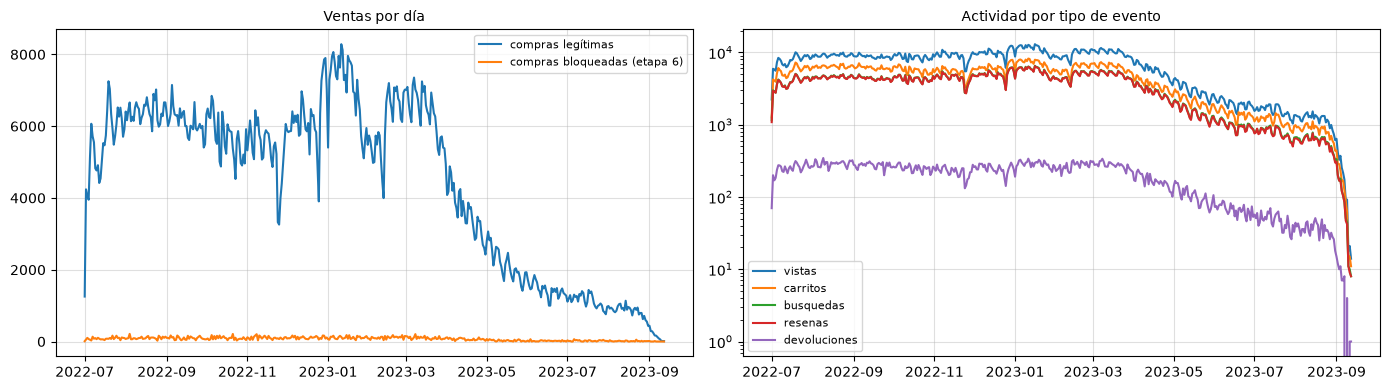

In [10]:
# 6.1 Panel de ventas, actividad y stock
t0 = time.perf_counter()
panel = servicio.panel_ventas_actividad(k=10)
print(f"Panel calculado en {time.perf_counter() - t0:.1f} s")
display(pd.Series(panel["resumen"]).to_frame("valor"))
display(pd.DataFrame(panel["top_productos"]))
display(pd.DataFrame(panel["por_categoria"]))
display(pd.DataFrame(panel["agotados"]))

por_dia = pd.DataFrame(panel["por_dia"]).assign(fecha=lambda d: pd.to_datetime(d["fecha"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(por_dia["fecha"], por_dia["compras"], label="compras legítimas")
axes[0].plot(por_dia["fecha"], por_dia["compras_bloqueadas"], label="compras bloqueadas (etapa 6)")
axes[0].set_title("Ventas por día", fontsize=10); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.4)
for columna in ("vistas", "carritos", "busquedas", "resenas", "devoluciones"):
    axes[1].plot(por_dia["fecha"], por_dia[columna], label=columna)
axes[1].set_yscale("log"); axes[1].set_title("Actividad por tipo de evento", fontsize=10)
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.4)
fig.tight_layout(); fig.savefig(R / "panel_ventas.png", dpi=150); plt.show()

## Paso 7. Centro de monitoreo de fraude (etapa 6)

El servicio consulta las decisiones emitidas por el detector probabilístico de la etapa 6 (Count-Min Sketch + Bloom Filter): bloqueos automáticos y operaciones que quedan en revisión manual (decisión `revisar`). La precisión de los bloqueos se mide con la etiqueta `fraude_real` del generador. Vale 1 por construcción, porque la etapa 6 solo bloquea operaciones de las cuentas, tarjetas o dispositivos de la lista de señalados, y esa lista es la que define el fraude (informe de la etapa 6).

In [11]:
# 7.1 Resumen de las alertas de la etapa 6
resumen_f = servicio.resumen_fraude()
print("Resumen de seguridad:")
print(f"  Total de alertas: {resumen_f['resumen'].get('total_alertas', 0):,}")
print(f"  Bloqueadas:       {resumen_f['resumen'].get('bloqueadas', 0):,} "
      f"(precisión medida con fraude_real: {resumen_f['resumen'].get('precision_bloqueos', 0):.4f})")
print(f"  En revisión:      {resumen_f['resumen'].get('en_revision', 0):,}")
print(f"  Aprobadas:        {resumen_f['resumen'].get('aprobadas', 0):,}")

print("\nMuestra de alertas procesadas:")
display(pd.DataFrame(resumen_f["muestra"]).head(6))

Resumen de seguridad:
  Total de alertas: 47,710
  Bloqueadas:       41,532 (precisión medida con fraude_real: 1.0000)
  En revisión:      6,178
  Aprobadas:        0

Muestra de alertas procesadas:


,event_id,order_id,user_id,decision,motivos,fraude_real,estimado_cms
0,e000001899,o00000292,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,[cuenta],True,1.0
1,e000001904,o00000296,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,[cuenta],True,NaN
2,e000001902,o00000295,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,[cuenta],True,2.0
3,e000001903,o00000296,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,[cuenta],True,3.0
4,e000001905,o00000297,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,[cuenta],True,4.0
5,e000001901,o00000294,APOFB6P2MCUBESJ7DYTZHQOO37JT,bloquear,"[cuenta, rafaga]",True,5.0


## Paso 8. Salidas de la etapa 9 y dashboard

`ejecutar_etapa` carga el servicio, resuelve las consultas de demostración (autocompletado exacto y difuso, búsqueda, recomendación, filtro por precio y arranque en frío), calcula el panel de ventas, mide las latencias del servicio con repeticiones y escribe:
1. `metricas.json`: latencias p50 y p95, tamaños de los índices y pesos del scoring.
2. `demo_consultas.json`: consultas precalculadas, panel de ventas y alertas.
3. `visualizador/dashboard_etapa_9_servicio.html`: el dashboard, generado por `src/etapa_9/dashboard.py` con los dos archivos anteriores incrustados.

In [12]:
# 8.1 Ejecución de la etapa y verificación de las salidas
metricas_etapa9 = ejecutar_etapa(categoria=CATEGORIA, raiz=RAIZ)

ruta_metricas = DIR_ETAPA9 / "metricas.json"
ruta_demo = DIR_ETAPA9 / "demo_consultas.json"
for r in (ruta_metricas, ruta_demo, RUTA_DASHBOARD):
    tam_kb = r.stat().st_size / 1024
    print(f"✓ {r.name:30s} | Tamaño: {tam_kb:7.1f} KB")

print("\nMétricas registradas:")
print(json.dumps(metricas_etapa9, indent=2, ensure_ascii=False))

--- Iniciando Etapa 9: Servicio y Visualización (Office_Products) ---


ServicioEcommerce inicializado en 102.76 s


✓ Métricas guardadas en: D:\projects\alg-final-project\data\interim\Office_Products\etapa_9\metricas.json
✓ Demos guardadas en: D:\projects\alg-final-project\data\interim\Office_Products\etapa_9\demo_consultas.json
✓ Dashboard generado en: D:\projects\alg-final-project\visualizador\dashboard_servicio.html
Etapa 9 completada en 162.40 s


✓ metricas.json                  | Tamaño:     2.0 KB
✓ demo_consultas.json            | Tamaño:   225.3 KB
✓ dashboard_servicio.html        | Tamaño:   180.3 KB

Métricas registradas:
{
  "categoria": "Office_Products",
  "tiempo_inicializacion_s": 102.762,
  "terminos_trie_indexados": 585983,
  "nodos_trie_radix": 831377,
  "productos_indexados_busqueda": 710468,
  "vocabulario_busqueda": 336422,
  "postings_busqueda": 11839094,
  "vocabulario_correccion": 53341,
  "latencia_autocompletado_p50_ms": 0.0043,
  "latencia_autocompletado_p95_ms": 0.0044,
  "latencia_autocompletado_difuso_p50_ms": 2.9475,
  "latencia_autocompletado_difuso_p95_ms": 3.5625,
  "latencia_recomendacion_topk_ms": 1.433,
  "latencia_recomendacion_topk_p95_ms": 1.819,
  "latencia_busqueda_topk_p50_ms": 6.266,
  "latencia_busqueda_topk_p95_ms": 6.881,
  "latencia_rango_precio_ms": 289.742,
  "segundos_panel_ventas": 58.3,
  "scoring_pesos": {
    "similitud": 0.35,
    "relacionados": 0.25,
    "pagerank": 0.2,
   

## Paso 9. Experimentos de escalabilidad

### Diseño del experimento

| Experimento | Estructura | Línea base | Complejidad esperada |
| --- | --- | --- | --- |
| 9.1 Trie | Trie radix con caché Top-K | — | Construcción $O(N \cdot (L + hM))$; consulta $O(L + k)$, independiente de $N$ |
| 9.2 Top-K | `TopKHeap` (MinHeap de tamaño K) | `sorted()`, `heapq.nlargest` y `np.argpartition` | $O(N \log K)$ frente a $O(N \log N)$, $O(N \log K)$ en C y $O(N)$ en C |
| 9.3 Difuso | Autocompletado Damerau-OSA sobre el Trie | Búsqueda exacta | Crece con los caracteres recorridos dentro de la banda de distancia $d$ |

**Datos.** El Trie se construye con 1 000 a 250 000 términos del catálogo real (marcas, categorías, palabras y bigramas de los títulos). El Top-K se mide con $N$ de 1 000 a 1 000 000 scores al azar y $K \in \{5, 10, 20, 50\}$; las líneas base, con $K = 10$. El difuso usa 300 consultas con un error de tipeo sintético.

**Repeticiones y medición.** El mismo protocolo de la etapa 8 (`src/etapa_8/benchmark.py`): la primera ejecución fija cuántas repeticiones caben en 120 s, con un máximo de 100; tiempo con `time.perf_counter` y el recolector de basura desactivado; memoria con `tracemalloc` en una pasada aparte. La latencia del Trie se mide en 100 bloques de 10 consultas. La versión anterior medía cada construcción y cada ordenamiento una sola vez.

In [13]:
# 9.1 a 9.3: Trie, Top-K y autocompletado difuso
terminos = benchmark.extraer_vocabulario_catalogo(max_terminos=300_000)
df_trie = resultados(R / "escala_trie.csv", lambda: benchmark.benchmark_trie(terminos),
                     requeridas=["tiempo_construccion_ms_std", "latencia_media_us_repeticiones"])
df_topk = resultados(R / "escala_topk.csv", benchmark.benchmark_topk,
                     requeridas=["ms_topk_heap_std", "ms_sorted_repeticiones"])
df_difuso = resultados(R / "difuso_trie.csv", lambda: benchmark.benchmark_difuso(terminos))
df_comp = df_topk[df_topk["k"] == 10].reset_index(drop=True)
df_comp.to_csv(R / "comparacion_sorting.csv", index=False)

print("--- ESCALA TRIE ---")
display(df_trie)

print("\n--- TOP-K HEAP FRENTE AL ORDENAMIENTO COMPLETO (K = 10) ---")
display(df_comp)

print("\n--- AUTOCOMPLETADO DIFUSO ---")
display(df_difuso)

Vocabulario extraído del catálogo: 300,000 términos
escala_trie.csv es de una versión anterior del experimento y se mide de nuevo

--- Ejecutando Benchmark de Escalabilidad del Trie ---


  N = 1,000 | Construcción: 9.9 ms (100 repeticiones) | Memoria pico: 0.62 MB | Latencia p50: 3.90 µs


  N = 10,000 | Construcción: 120.3 ms (100 repeticiones) | Memoria pico: 6.06 MB | Latencia p50: 3.90 µs


  N = 50,000 | Construcción: 751.3 ms (100 repeticiones) | Memoria pico: 29.84 MB | Latencia p50: 4.10 µs


  N = 100,000 | Construcción: 1612.0 ms (71 repeticiones) | Memoria pico: 59.49 MB | Latencia p50: 3.90 µs


  N = 250,000 | Construcción: 4551.1 ms (25 repeticiones) | Memoria pico: 148.14 MB | Latencia p50: 3.70 µs


... (9 outputs left out)


--- TOP-K HEAP FRENTE AL ORDENAMIENTO COMPLETO (K = 10) ---


,n,k,ms_topk_heap,ms_topk_heap_std,ms_topk_heap_repeticiones,ms_topk_heap_primera,mem_pico_bytes,ms_sorted,ms_sorted_std,ms_sorted_repeticiones,...,ms_numpy,ms_numpy_std,ms_numpy_repeticiones,ms_numpy_primera,speedup_vs_sorted,speedup_numpy_vs_heap,reemplazos_heap_k10,reemplazos_teoricos_k10,procesador,python
0,1000,10,0.568586,0.104092,100,0.5069,2456,0.221720,0.057922,100,...,0.097717,0.027067,100,0.1006,0.389950,5.818701,48,46.051702,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0
1,10000,10,4.202635,0.582404,100,3.8101,2456,1.913986,0.425063,100,...,0.132098,0.032283,100,0.1167,0.455425,31.814520,66,69.077553,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0
2,50000,10,17.783687,1.201381,100,17.6345,2488,10.325799,0.785113,100,...,0.340161,0.176214,100,0.2926,0.580633,52.280206,76,85.171932,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0
3,100000,10,34.373120,1.626308,100,35.3619,2488,23.600020,1.465080,100,...,0.431000,0.080046,100,0.3964,0.686584,79.752015,94,92.103404,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0
4,500000,10,164.826224,4.993491,100,185.2114,2488,155.214114,3.465355,100,...,4.149634,0.290919,100,4.2754,0.941683,39.720665,101,108.197783,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0
5,1000000,10,323.679950,7.798429,100,329.0572,2488,381.707215,56.941147,100,...,12.345794,1.903085,100,12.3745,1.179274,26.217832,111,115.129255,"AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD",3.12.0



--- AUTOCOMPLETADO DIFUSO ---


,max_dist,consultas,terminos,nodos_radix,latencia_p50_us,latencia_p95_us,latencia_p99_us,acierto_prefijo_original_top5,consultas_sin_resultado_exacto
0,1,300,292300,375715,431.729004,684.748206,791.730917,0.896667,0.940000
1,2,300,292300,375715,1934.271000,3018.218101,3962.910415,0.946667,0.956667


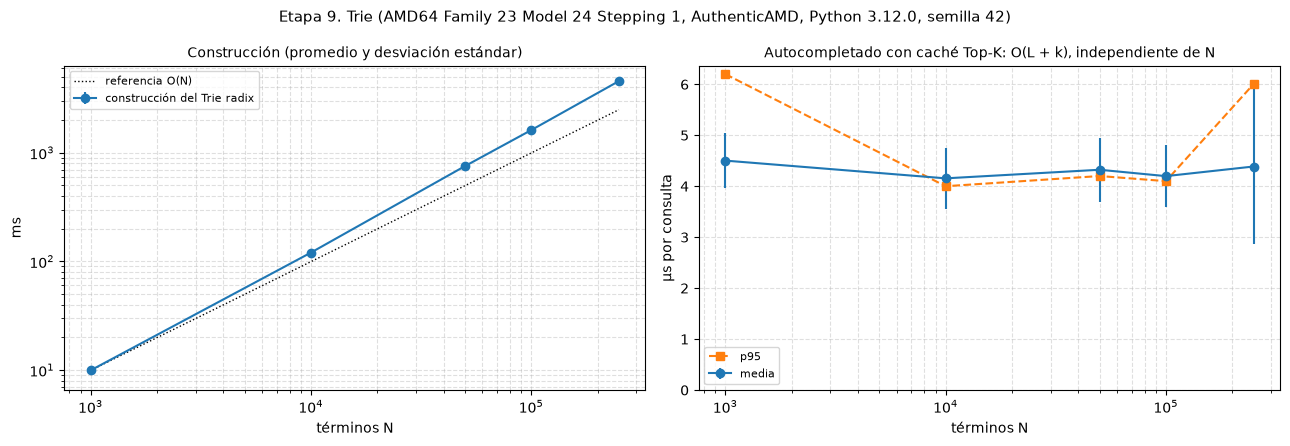

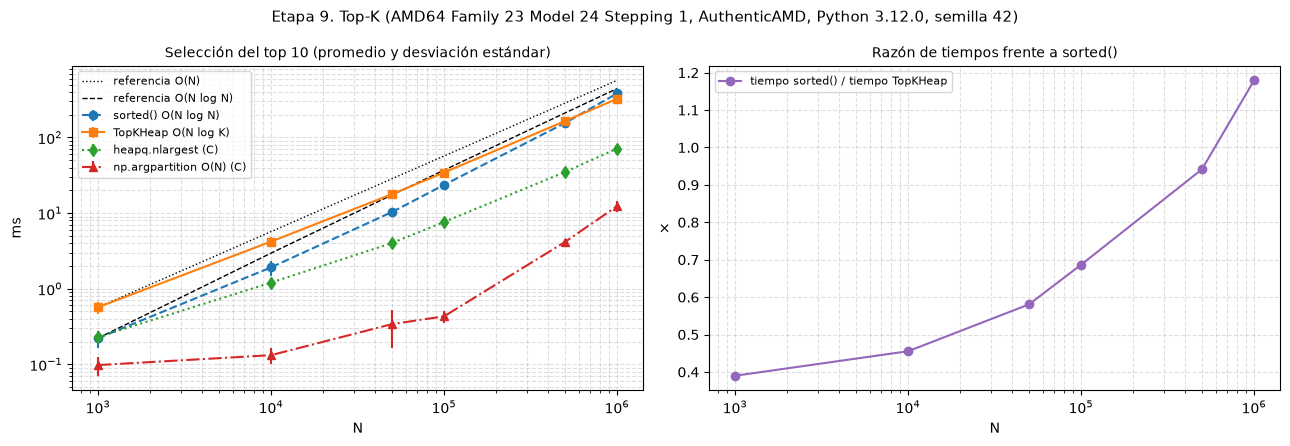

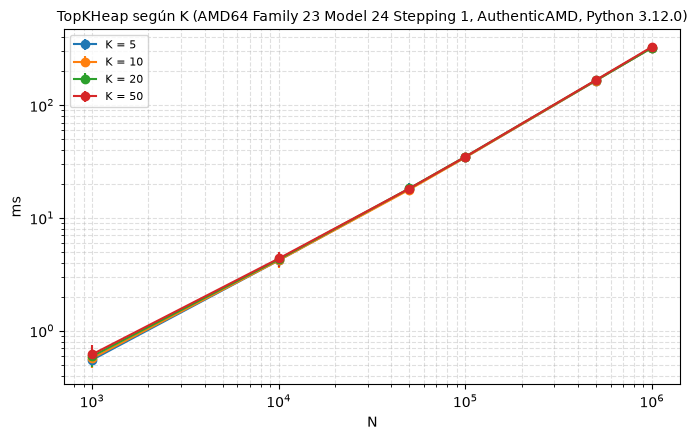

,medida,pendiente_log_log
0,construcción del Trie,1.11
1,consulta del Trie (media),-0.01
2,TopKHeap (K = 10),0.92
3,sorted(),1.08
4,heapq.nlargest,0.83
5,np.argpartition,0.70


In [14]:
# 9.4 Gráficas log-log con rectas de referencia y pendientes
def ejes_loglog(ax, titulo, ylabel, xlabel="N"):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.grid(True, which="both", linestyle="--", alpha=0.4)
    ax.legend(fontsize=8)


def referencia(ax, x, y, etiqueta, nlogn=False):
    """Recta O(x), u O(x log x) con nlogn, que pasa por el primer punto medido."""
    forma = x * np.log(x) if nlogn else x
    ax.plot(x, y.iloc[0] * forma / forma.iloc[0], "k--" if nlogn else "k:", lw=1, label=etiqueta)


def pendiente(x, y):
    """Pendiente del ajuste log-log de y frente a x."""
    return round(float(np.polyfit(np.log10(x), np.log10(y), 1)[0]), 2)


# Trie: construcción y latencia
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = df_trie["n_terminos"]
axes[0].errorbar(x, df_trie["tiempo_construccion_ms"], yerr=df_trie["tiempo_construccion_ms_std"], fmt="o-",
                 label="construcción del Trie radix")
referencia(axes[0], x, df_trie["tiempo_construccion_ms"], "referencia O(N)")
ejes_loglog(axes[0], "Construcción (promedio y desviación estándar)", "ms", "términos N")
axes[1].errorbar(x, df_trie["latencia_media_us"], yerr=df_trie["latencia_media_us_std"], fmt="o-", label="media")
axes[1].plot(x, df_trie["latencia_p95_us"], "s--", label="p95")
axes[1].set_xscale("log"); axes[1].set_ylim(bottom=0)
axes[1].set_title("Autocompletado con caché Top-K: O(L + k), independiente de N", fontsize=10)
axes[1].set_xlabel("términos N"); axes[1].set_ylabel("µs por consulta")
axes[1].grid(True, which="both", linestyle="--", alpha=0.4); axes[1].legend(fontsize=8)
fig.suptitle(f"Etapa 9. Trie ({plataforma_de(df_trie)}, semilla {SEED})", fontsize=11)
fig.tight_layout(); fig.savefig(R / "escala_trie.png", dpi=150); plt.show()

# Top 10: TopKHeap frente a las líneas base
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = df_comp["n"]
for columna, etiqueta, fmt in (("ms_sorted", "sorted() O(N log N)", "o--"), ("ms_topk_heap", "TopKHeap O(N log K)", "s-"),
                               ("ms_nlargest", "heapq.nlargest (C)", "d:"), ("ms_numpy", "np.argpartition O(N) (C)", "^-.")):
    axes[0].errorbar(x, df_comp[columna], yerr=df_comp[f"{columna}_std"], fmt=fmt, label=etiqueta)
referencia(axes[0], x, df_comp["ms_topk_heap"], "referencia O(N)")
referencia(axes[0], x, df_comp["ms_sorted"], "referencia O(N log N)", nlogn=True)
ejes_loglog(axes[0], "Selección del top 10 (promedio y desviación estándar)", "ms")
axes[1].plot(x, df_comp["speedup_vs_sorted"], "o-", color="#9467bd", label="tiempo sorted() / tiempo TopKHeap")
axes[1].set_xscale("log"); axes[1].set_title("Razón de tiempos frente a sorted()", fontsize=10)
axes[1].set_xlabel("N"); axes[1].set_ylabel("×")
axes[1].grid(True, which="both", linestyle="--", alpha=0.4); axes[1].legend(fontsize=8)
fig.suptitle(f"Etapa 9. Top-K ({plataforma_de(df_comp)}, semilla {SEED})", fontsize=11)
fig.tight_layout(); fig.savefig(R / "comparacion_sorting.png", dpi=150); plt.show()

# TopKHeap con distintos K
fig, ax = plt.subplots(figsize=(7, 4.5))
for k_val in sorted(df_topk["k"].unique()):
    sub = df_topk[df_topk["k"] == k_val]
    ax.errorbar(sub["n"], sub["ms_topk_heap"], yerr=sub["ms_topk_heap_std"], fmt="o-", label=f"K = {k_val}")
ejes_loglog(ax, f"TopKHeap según K ({plataforma_de(df_topk)})", "ms")
fig.tight_layout(); fig.savefig(R / "escala_topk.png", dpi=150); plt.show()

display(pd.DataFrame([
    {"medida": "construcción del Trie", "pendiente_log_log": pendiente(df_trie["n_terminos"], df_trie["tiempo_construccion_ms"])},
    {"medida": "consulta del Trie (media)", "pendiente_log_log": pendiente(df_trie["n_terminos"], df_trie["latencia_media_us"])},
    {"medida": "TopKHeap (K = 10)", "pendiente_log_log": pendiente(df_comp["n"], df_comp["ms_topk_heap"])},
    {"medida": "sorted()", "pendiente_log_log": pendiente(df_comp["n"], df_comp["ms_sorted"])},
    {"medida": "heapq.nlargest", "pendiente_log_log": pendiente(df_comp["n"], df_comp["ms_nlargest"])},
    {"medida": "np.argpartition", "pendiente_log_log": pendiente(df_comp["n"], df_comp["ms_numpy"])},
]))

### Lectura de los resultados

- **9.1, Trie.** La construcción crece con pendiente log-log 1.11: el tiempo por inserción sube de 9.9 µs con 1 000 términos a 18.2 µs con 250 000, porque cada inserción actualiza la caché Top-K de más nodos a lo largo de su camino ($hM$). Con 250 000 términos tarda 4.55 ± 0.07 s (25 repeticiones) y ocupa 148 MB, unos 620 bytes por término y 500 por nodo radix. La consulta no depende de $N$ (pendiente −0.01): la media está entre 4.2 y 4.5 µs y el p95 entre 4.0 y 6.2 µs en todos los tamaños, lo esperado para $O(L + k)$ con la caché.
- **9.2, Top-K.** Las pendientes son 0.92 para `TopKHeap`, 1.08 para `sorted()`, 0.83 para `heapq.nlargest` y 0.70 para `np.argpartition`. `TopKHeap` recién supera a `sorted()` con 1 M de scores (323.7 ± 7.8 ms frente a 381.7 ± 56.9 ms, razón 1.18); por debajo de 500 000 el ordenamiento en C gana a pesar de su $O(N \log N)$, porque el heap paga una llamada de Python por elemento. Las versiones en C quedan muy por delante: `heapq.nlargest`, el mismo algoritmo, tarda 71 ms con 1 M, y `np.argpartition` 12 ms, 26 veces menos que `TopKHeap`. El tiempo no cambia con K entre 5 y 50 (de 323 a 329 ms con 1 M) y la memoria pico es $O(K)$, de 1.6 KB a 10 KB. Los reemplazos en el heap coinciden con la esperanza $K \ln(N/K)$: 111 frente a 115 con 1 M. `TopKHeap` se justifica por su memoria acotada y porque procesa los candidatos en flujo, no por velocidad.
- **9.3, difuso.** Sobre 292 300 términos, la latencia p50 es de 0.43 ms con $d = 1$ y 1.9 ms con $d = 2$, y el p95, de 0.68 ms y 3.0 ms. El prefijo original aparece en el top 5 en el 89.7 % de las consultas con $d = 1$ y en el 94.7 % con $d = 2$; sin el difuso, entre el 94 % y el 96 % de las consultas con un error de tipeo no tendrían ningún resultado. El servicio usa $d = 1$, unas 4.5 veces más rápido en la mediana. Esta tabla viene de la medición anterior, porque el código del difuso no cambió.

## Paso 10. Auditoría técnica y calibración del scoring

Cambios verificados en esta sección (auditoría de las etapas 8 y 9 del 2026-10-27 y revisión técnica del 2026-10-28):
1. **Trie radix.** El Trie de un carácter por nodo creaba 7.2 M nodos para el catálogo completo (90 % unarios, 3.5 GB); la compresión radix deja unos 0.83 M con la misma semántica (celda 10.1).
2. **Autocompletado difuso.** Damerau-Levenshtein (OSA) sobre el Trie con banda de Ukkonen y poda exacta; solo se activa si la búsqueda exacta no llena $k$.
3. **Búsqueda por índice invertido.** La búsqueda anterior puntuaba $0.5 + 0.5 \cdot S_{pr}$ (relevancia constante) y completaba con el prefijo `query[:3]`.
4. **Calibración del scoring.** Partición temporal 80/20 de órdenes, con la regla de adopción de pesos fijada antes de medir (`evaluacion_scoring.py`).
5. **Evaluación con un objetivo real.** El siguiente producto que reseña cada usuario, con el grafo de co-reseñas como fuente alternativa de co-compra (`evaluacion_real.py`), y el análisis descriptivo de los campos reales del dataset (`analisis_campos_reales.py`).
6. **S_sim corregido.** Las dos evaluaciones se repiten con $S_{\text{sim}} = 1 - d^2/2$; sus resúmenes lo registran en el campo `s_sim`, y un resultado guardado sin ese campo se mide de nuevo.

In [15]:
# 10.1 Tamaño del Trie radix y del índice invertido sobre el catálogo completo
print(f"Términos en el Trie:        {len(servicio.trie):,}")
print(f"Nodos del Trie radix:       {servicio.trie.n_nodos:,}")
print(f"Productos en el índice:     {servicio.indice.n_docs:,}")
print(f"Vocabulario / postings:     {len(servicio.indice.vocabulario):,} / {len(servicio.indice.postings):,}")

# 10.2 Autocompletado exacto frente a difuso (d = 1)
for consulta in ["stapel", "brotehr", "pilto g2", "scoth tape"]:
    exactas = servicio.trie.autocompletar(consulta, k=3)
    difusas = servicio.autocompletar(consulta, k=3)
    print(f"{consulta!r:14s} exactas={len(exactas)} difusas={[(s['termino'], s.get('distancia', 0)) for s in difusas]}")

display(df_difuso)

Términos en el Trie:        585,983
Nodos del Trie radix:       831,377
Productos en el índice:     710,468
Vocabulario / postings:     336,422 / 11,839,094
'stapel'       exactas=0 difusas=[('STAPENS', 1), ('STAPLES', 1), ('Stapex', 1)]
'brotehr'      exactas=0 difusas=[('BROTHER', 1), ('Brother', 1), ('Brother International Corp.', 1)]
'pilto g2'     exactas=0 difusas=[('PILOT G2 Premium Refillable', 1), ('Pilot, G2 Premium Gel', 1), ('Pilot, G2 Gel Ink', 1)]
'scoth tape'   exactas=0 difusas=[('Scotch Tape Dispenser in', 1), ('Scotch Tape Runner Refill.31', 1), ('SCOTCH TAPE TRANSPARENT CRYSTAL', 1)]


,max_dist,consultas,terminos,nodos_radix,latencia_p50_us,latencia_p95_us,latencia_p99_us,acierto_prefijo_original_top5,consultas_sin_resultado_exacto
0,1,300,292300,375715,431.729004,684.748206,791.730917,0.896667,0.940000
1,2,300,292300,375715,1934.271000,3018.218101,3962.910415,0.946667,0.956667


In [16]:
# 10.3 Búsqueda con corrección ortográfica por token
for consulta in ["toner brother", "toner brtoher", "stapler swinglien"]:
    print(f"{consulta!r} -> {' '.join(servicio.corregir_consulta(consulta))!r}")
    display(pd.DataFrame(servicio.buscar(consulta, k=5))[["rango", "score", "titulo", "tienda"]])

'toner brother' -> 'toner brother'


,rango,score,titulo,tienda
0,1,1.0000,TN436 ColorKing Compatible Toner Cartridge Rep...,Colorking
1,2,0.9526,ColorKing Compatible Toner Cartridge Replaceme...,Colorking
2,3,0.9442,GOTOBY TN760 Toner Cartridge Replacement Compa...,GOTOBY
3,4,0.9412,MCYCOLOR DR730 Drum Unit Compatible Replacemen...,MCYCOLOR
4,5,0.9358,Brother Genuine Cartridge TN760 High Yield Bla...,Brother


'toner brtoher' -> 'toner brother'


,rango,score,titulo,tienda
0,1,1.0000,TN436 ColorKing Compatible Toner Cartridge Rep...,Colorking
1,2,0.9526,ColorKing Compatible Toner Cartridge Replaceme...,Colorking
2,3,0.9442,GOTOBY TN760 Toner Cartridge Replacement Compa...,GOTOBY
3,4,0.9412,MCYCOLOR DR730 Drum Unit Compatible Replacemen...,MCYCOLOR
4,5,0.9358,Brother Genuine Cartridge TN760 High Yield Bla...,Brother


'stapler swinglien' -> 'stapler swingline'


,rango,score,titulo,tienda
0,1,0.9489,"Swingline Stapler, 747 Iconic Desktop Stapler,...",Swingline
1,2,0.9389,"Swingline Stapler, 6 Pack, Desktop Stapler, 25...",Swingline
2,3,0.9370,"Swingline Mini Stapler, Tot, 12 Sheet Capacity...",Swingline
3,4,0.9349,"Swingline Stapler, 747 Classic Desktop Stapler...",Swingline
4,5,0.9263,"Swingline Stapler, 20 Sheet Capacity, Light Du...",Swingline


In [17]:
# 10.4 Calibración temporal del scoring híbrido (prueba, Recall@10 por grupo de co-compras del ancla)
ruta_resumen_cal = R / "calibracion_scoring_resumen.json"
resultados_archivos([R / "calibracion_scoring.csv", R / "calibracion_lineas_base.csv", ruta_resumen_cal],
                    evaluacion_scoring.main,
                    vigente=lambda: "s_sim" in json.loads(ruta_resumen_cal.read_text(encoding="utf-8")))
cal = pd.read_csv(R / "calibracion_scoring.csv")
prueba = cal[cal["conjunto"] == "prueba"]
display(prueba.pivot_table(index=["relacionados", "normalizacion_pr", "kappa"],
                           columns="grupo", values="recall@10").round(4))
display(pd.read_csv(R / "calibracion_lineas_base.csv"))
print(json.dumps(json.loads(ruta_resumen_cal.read_text(encoding="utf-8")), indent=2))

entrenamiento: 131,854 nodos, 658,701 aristas; pares de prueba: 186,285 (75.2 s)


relacionados temporales: 65,248 productos (251.8 s)


ServicioEcommerce inicializado en 43.90 s


  grilla fuga/max lista (358 s)


  grilla fuga/log lista (420 s)


  grilla fuga/percentil lista (482 s)


... (10 outputs left out)

Resultados guardados en calibracion_scoring.csv, calibracion_lineas_base.csv, calibracion_scoring_resumen.json


grupo                                   3-9    >=10  cold_start    n<=2
relacionados normalizacion_pr kappa                                    
fuga         log              0.0    0.0741  0.1116      0.0022  0.0275
                              1.0    0.0693  0.1076      0.0022  0.0194
                              2.0    0.0637  0.1041      0.0022  0.0125
                              5.0    0.0455  0.0936      0.0022  0.0043
                              10.0   0.0293  0.0798      0.0022  0.0014
...                                     ...     ...         ...     ...
temporal     percentil        2.0    0.0706  0.1173      0.0001  0.0181
                              5.0    0.0611  0.1103      0.0001  0.0099
                              10.0   0.0480  0.1010      0.0001  0.0061
                              20.0   0.0347  0.0872      0.0001  0.0028
                              50.0   0.0222  0.0629      0.0001  0.0015

[63 rows x 4 columns]

,relacionados,modelo,pesos,recall@10,ndcg@10,cobertura_catalogo@10,gini_recomendaciones,pares_entrenamiento,tasa_positivos
0,fuga,solo_similitud,"[1.0, 0.0, 0.0, 0.0]",0.000071,0.000086,0.754063,0.386378,NaN,NaN
1,fuga,solo_relacionados,"[0.0, 1.0, 0.0, 0.0]",0.261392,0.239526,0.679299,0.381731,NaN,NaN
2,fuga,solo_pagerank,"[0.0, 0.0, 1.0, 0.0]",0.193863,0.194438,0.556678,0.546133,NaN,NaN
3,fuga,solo_cocompra,"[0.0, 0.0, 0.0, 1.0]",0.131522,0.133171,0.705342,0.445033,NaN,NaN
4,fuga,hibrido_estatico_log,"[0.35, 0.25, 0.2, 0.2]",0.064964,0.074186,0.679393,0.452267,NaN,NaN
5,fuga,logistica_libre,"[-14.8758, 34.9283, 5.6257, -1.8077]",0.280281,0.270828,0.628240,0.477197,411490.0,0.086877
6,fuga,logistica_no_negativa,"[0.0, 0.8985, 0.1015, 0.0]",0.249905,0.239754,0.619471,0.488201,411490.0,0.086877
7,temporal,solo_similitud,"[1.0, 0.0, 0.0, 0.0]",0.000071,0.000086,0.761548,0.386378,NaN,NaN
8,temporal,solo_relacionados,"[0.0, 1.0, 0.0, 0.0]",0.030803,0.037290,0.716160,0.380346,NaN,NaN
9,temporal,solo_pagerank,"[0.0, 0.0, 1.0, 0.0]",0.097468,0.124712,0.597862,0.532952,NaN,NaN


{
  "fuga": {
    "mejor_kappa": 0.0,
    "mejor_normalizacion": "percentil"
  },
  "temporal": {
    "mejor_kappa": 0.0,
    "mejor_normalizacion": "log"
  },
  "sin": {
    "mejor_kappa": 0.0,
    "mejor_normalizacion": "log"
  },
  "regla_adopcion": {
    "pesos_candidatos": [
      0.0,
      0.0,
      0.9271,
      0.0729
    ],
    "mejora_recall": 0.5630929657894621,
    "mejora_ndcg": 0.7574651907783572,
    "caida_cobertura": 0.12375087576975552,
    "adoptar": true
  },
  "h3_cold_start_identico": true,
  "cobertura_candidatos": 0.6340343082396566,
  "productos_relacionados_temporales": 65248,
  "anclas": 59869,
  "s_sim": "coseno: 1 - d^2 / 2",
  "segundos": 966.5110793998465
}


In [18]:
# 10.5 Evaluación con un objetivo real (siguiente reseña) y análisis de los campos reales
ruta_resumen_real = R / "evaluacion_real_resumen.json"
resultados_archivos([R / "evaluacion_real.csv", ruta_resumen_real], evaluacion_real.main,
                    vigente=lambda: "s_sim" in json.loads(ruta_resumen_real.read_text(encoding="utf-8")))
ruta_campos = R / "analisis_campos_reales.json"
resultados_archivos([ruta_campos], analisis_campos_reales.main)

real = pd.read_csv(R / "evaluacion_real.csv")
display(real[(real["generador"] == "ampliado") & (real["lambda_novedad"].isin([0.0, 0.3]))]
        [["fuente", "modelo", "lambda_novedad", "hitrate@10", "ndcg@10", "cobertura_catalogo@10", "gini_exposicion"]])
print(json.dumps(json.loads(ruta_resumen_real.read_text(encoding="utf-8"))["regla_fuente_cocompra"], indent=2))
campos = json.loads(ruta_campos.read_text(encoding="utf-8"))
print(f"Gini de reseñas por producto: {campos['gini_resenas_por_producto']:.3f}; el 1 % de los productos "
      f"concentra el {campos['fraccion_resenas_top1pct_productos']:.1%} de las reseñas")

servicio.cerrar()

co-reseñas de entrenamiento: 522,795 nodos / 4,130,140 aristas (32 s)


co-compra sintética sin futuro: 531,469 nodos / 4,827,476 aristas (980 s)


[base] candidatos listos (451 por ancla, 12 s)


{'generador': 'base', 'modelo': 'solo_similitud', 'lambda_novedad': 0.0, 'pesos_sim_pr_co_cat': [1.0, 0.0, 0.0, 0.0], 'hitrate@10': 0.006, 'ndcg@10': np.float64(0.0036238690399394294), 'cobertura_catalogo@10': 0.2605477057610367, 'gini_exposicion': 0.5675747119134501, 'diversidad_categorias_lista': 0.29035916666666667, 'relevante_en_candidatos': 0.033725}


{'generador': 'base', 'modelo': 'solo_pagerank', 'lambda_novedad': 0.0, 'pesos_sim_pr_co_cat': [0.0, 1.0, 0.0, 0.0], 'hitrate@10': 0.0034, 'ndcg@10': np.float64(0.0018188583339511088), 'cobertura_catalogo@10': 0.017598284736681825, 'gini_exposicion': 0.9043336768483048, 'diversidad_categorias_lista': 0.6464916666666667, 'relevante_en_candidatos': 0.033725}


{'generador': 'base', 'modelo': 'solo_coresena', 'lambda_novedad': 0.0, 'pesos_sim_pr_co_cat': [0.0, 0.0, 1.0, 0.0], 'hitrate@10': 0.006275, 'ndcg@10': np.float64(0.003891221919123742), 'cobertura_catalogo@10': 0.20183311339603816, 'gini_exposicion': 0.7024253879883777, 'diversidad_categorias_lista': 0.6996666666666667, 'relevante_en_candidatos': 0.033725}


... (40 outputs left out)

{
  "corte_timestamp_ms": 1661105063734.4,
  "pares_disponibles": 299548,
  "pares_evaluados": 80000,
  "pares_calibracion": 40000,
  "pares_prueba": 40000,
  "co_compra_sintetica": {
    "eventos": 83462478,
    "compras": 17344471,
    "compras_fraude_excluidas": 302141,
    "asins_vacios_descartados": 27537,
    "segundos_stream": 881.4396452000365,
    "segundos_grafo": 36.142731099855155
  },
  "coresena": {
    "nodos": 522795,
    "aristas": 4130140,
    "base": {
      "candidatos_por_ancla": 450.651775,
      "pares_logistica": 18110390,
      "tasa_positivos": 7.929150062477948e-05,
      "coef_logistica_libre_sim_pr_co_cat": [
        3.059521079072747,
        4.004385996739431,
        1.6591453866195074,
        1.4345367620513534
      ]
    },
    "ampliado": {
      "candidatos_por_ancla": 685.784825,
      "pares_logistica": 27578223,
      "tasa_positivos": 7.766997895404645e-05,
      "coef_logistica_libre_sim_pr_co_cat": [
        2.9531413260803676,
        4.2559

Resultados guardados en evaluacion_real.csv, evaluacion_real_resumen.json
Resultados leídos de analisis_campos_reales.json


,fuente,modelo,lambda_novedad,hitrate@10,ndcg@10,cobertura_catalogo@10,gini_exposicion
17,coresena,solo_similitud,0.0,0.005850,0.003545,0.221498,0.564093
18,coresena,solo_pagerank,0.0,0.004625,0.002855,0.007872,0.967459
19,coresena,solo_coresena,0.0,0.006875,0.004080,0.176431,0.704840
20,coresena,solo_categoria,0.0,0.001100,0.000462,0.098747,0.757862
21,coresena,hibrido_estatico,0.0,0.008850,0.004948,0.127104,0.750598
25,coresena,hibrido_estatico,0.3,0.007525,0.004510,0.184964,0.640523
27,coresena,logistica_libre,0.0,0.008700,0.004828,0.064470,0.840178
28,coresena,logistica_no_negativa,0.0,0.008700,0.004828,0.064448,0.840174
32,coresena,logistica_no_negativa,0.3,0.008250,0.004705,0.157391,0.680327
34,sintetico,solo_coresena,0.0,0.000425,0.000225,0.111787,0.730650


{
  "coresena": {
    "mejora_hitrate": 0.320175438596491,
    "mejora_ndcg": 0.3547749284959001,
    "subida_gini": 0.0420187338587672,
    "cumple": true
  },
  "ambos": {
    "mejora_hitrate": 0.05701754385964919,
    "mejora_ndcg": 0.11776253668796888,
    "subida_gini": 0.004243433302372535,
    "cumple": true
  },
  "fuente_adoptada": "coresena"
}
Gini de reseñas por producto: 0.838; el 1 % de los productos concentra el 41.8% de las reseñas


### Lectura de la auditoría y de la calibración

- **10.1 a 10.3.** El Trie radix indexa los 585 983 términos del catálogo en unos 0.83 M nodos, y el índice invertido cubre 710 468 productos. El autocompletado difuso recupera los términos correctos de consultas con un error de tipeo, como "brotehr" o "stapel", y la corrección por token convierte "toner brtoher" en "toner brother".
- **10.4, calibración.** En las tres variantes de relacionados el mejor $\kappa$ es 0, así que la credibilidad de la co-compra no ayuda, y la mejor normalización de PageRank es la logarítmica (la de percentiles con los relacionados con fuga). Con los relacionados sin futuro, las líneas base de una sola señal dan un Recall@10 de 0.0001 con solo similitud, 0.031 con solo relacionados, 0.097 con solo PageRank y 0.080 con solo co-compra; el híbrido estático da 0.063. La logística no negativa aprende pesos de 0 / 0 / 0.93 / 0.07 y llega a 0.099: la regla de adopción se cumple, con +56 % de Recall@10, +76 % de NDCG@10 y 12 % menos de cobertura. **Decisión declarada:** el servicio mantiene los pesos base. El objetivo de esta calibración son los grupos de co-compra del generador, que no dependen de los atributos, como muestra el Recall@10 casi nulo de la similitud; con el objetivo real de 10.5 el híbrido con similitud supera a solo PageRank. Antes de la corrección de S_sim la regla no se cumplía.
- **10.5, objetivo real.** Con el grafo de co-reseñas como fuente, el híbrido estático llega a un HitRate@10 de 0.0089 y un NDCG@10 de 0.0049, frente a 0.0046 y 0.0029 de solo PageRank y 0.0059 y 0.0035 de solo similitud. El premio a la novedad con $\lambda = 0.3$ baja el Gini de exposición de 0.75 a 0.64 y sube la cobertura de 0.13 a 0.18, a cambio de un HitRate de 0.0075. Con la co-compra sintética, la fuente del servicio, el híbrido da 0.0054 sin premio y 0.0057 con él, con el Gini de 0.68 a 0.60. La regla de la fuente de co-compra la cumplen las co-reseñas (+32 % de HitRate y +35 % de NDCG, con 0.04 más de Gini) y la suma de las dos fuentes, y elige las co-reseñas. El servicio sigue con la co-compra sintética (`FUENTE_COCOMPRA`), la decisión declarada en `src/etapa_9/service.py`: el enunciado define el grafo como productos de la misma orden y solo esa fuente pasa por el filtro de fraude de la etapa 6. Los datos reales están muy concentrados: el Gini de reseñas por producto es 0.838 y el 1 % de los productos reúne el 41.8 % de las reseñas.

## Resumen del pipeline de punta a punta (etapas 0 a 9)

| Etapa | Responsabilidad | Estructura principal | Complejidad | Uso en la etapa 9 |
| --- | --- | --- | --- | --- |
| **0** | Ingesta y buffer | ColaCircular con backpressure (sin descarte) | $O(1)$ | Stream de eventos sin pérdida, a través de las etapas 1 y 2 |
| **1** | Preprocesamiento | Merge sort y búsqueda binaria | $O(b \log b)$ por lote | Eventos limpios y deduplicados |
| **2** | Priorización | MinHeap con envejecimiento (aging) | $O(\log N)$ | Eventos en orden de servicio: ventas y actividad del panel |
| **3** | Almacenamiento | TablaHash, AlmacenCatalogo, caché LRU y CSR | $O(1)$ / $O(nnz)$ | Fichas de producto, stock y disponibilidad |
| **4** | Indexación | B+Tree en disco | $O(\log_B N + r/B)$ | Filtro por rango de precio en la recomendación y la búsqueda |
| **5** | Índice espacial | KD-Tree y KNN exacto | ≈ $O(\log N)$ con $d = 4$ | Arranque en frío por atributos |
| **6** | Filtrado probabilístico | Bloom Filter y Count-Min Sketch | $O(k)$ / $O(d)$ | 47 710 alertas y 31 994 órdenes bloqueadas; las compras bloqueadas no cuentan como ventas |
| **7** | Similitud aproximada | MinHash + LSH y HNSW | candidatos / ≈ $O(\log N)$ | Relacionados (S_rel) y similares (S_sim) |
| **8** | Grafo de dominio | PageRank (Power Iteration) y Louvain | $O(k (\|V\| + \|E\|))$ / ≈ $O(\|E\|)$ por pasada | Autoridad (S_pr), co-compra (S_co) y comunidad del producto |
| **9** | Servicio y visualización | Trie radix con caché Top-K (+ difuso OSA), índice invertido y TopKHeap | $O(L + k)$ consulta, $O(L + hM)$ inserción / $O(N \log K)$ | Autocompletado, búsqueda, ranking Top-K, panel de ventas y dashboard |

## Referencias

- **Cormen, T. H., Leiserson, C. E., Rivest, R. L., & Stein, C. (2022).** *Introduction to Algorithms* (4th ed.). MIT Press. Cap. 6 (Heapsort y colas de prioridad).
- **Fredkin, E. (1960).** Trie memory. *Communications of the ACM*, 3(9), 490-499. https://doi.org/10.1145/367390.367400
- **Knuth, D. E. (1998).** *The Art of Computer Programming, Volume 3: Sorting and Searching* (2nd ed.). Addison-Wesley. Cap. 6.3 (Digital Searching).
- **Manning, C. D., Raghavan, P., & Schütze, H. (2008).** *Introduction to Information Retrieval*. Cambridge University Press. Cap. 3 (Dictionaries and tolerant retrieval).
- **Morrison, D. R. (1968).** PATRICIA: Practical algorithm to retrieve information coded in alphanumeric. *Journal of the ACM*, 15(4), 514-534.
- **Ukkonen, E. (1985).** Algorithms for approximate string matching. *Information and Control*, 64(1-3), 100-118.